# 3.2 — Document Q&A with citations
**Session 3.2 · Demo + Lab**

What we'll do: connect the semantic search to the 2.4 assistant, make it cite its sources and say
"I don't know", then add a re-ranker and measure whether it was worth it. We decide the citation
rules and the questions.

## What we're building


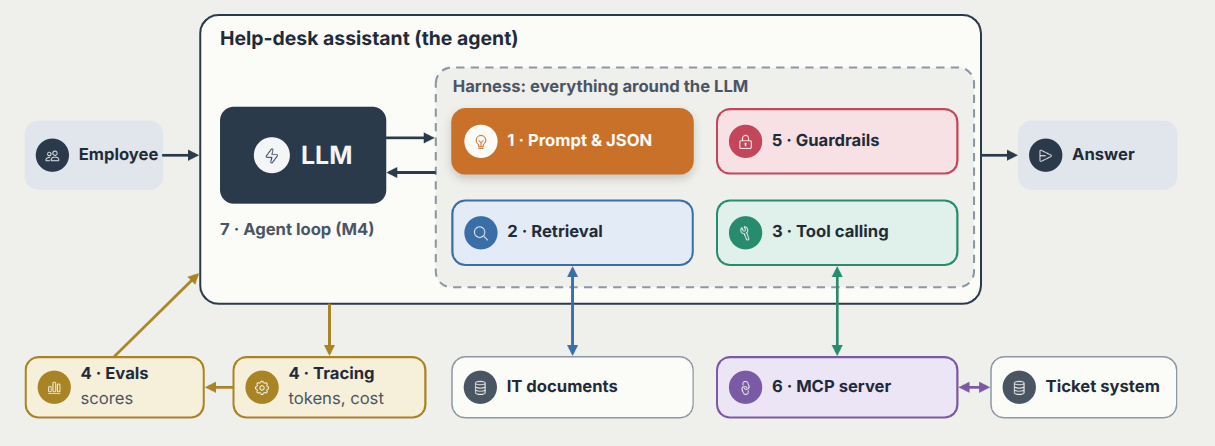

In [1]:
# @title Choose the model { display-mode: "form" }
MODEL_CHOICE = "Claude"  # @param ["Claude", "Open-weight model"]
OPEN_MODEL = "qwen3:8b"  # @param ["qwen3:8b", "qwen3:4b", "gpt-oss:20b", "llama3.1:8b"]

import importlib.util
import os
import shutil
import subprocess
import sys
import time

import requests
from IPython.display import HTML, display

OLLAMA = "http://127.0.0.1:11434"


def ollama_running():
    try:
        return requests.get(f"{OLLAMA}/api/tags", timeout=5).ok
    except requests.RequestException:
        return False


def start_ollama():
    """Install Ollama if needed, start it, and download the model."""
    if shutil.which("ollama") is None:
        subprocess.run("apt-get install -y -qq pciutils zstd > /dev/null", shell=True)
        subprocess.run("curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1", shell=True)
    if not ollama_running():
        settings = {"OLLAMA_HOST": "127.0.0.1:11434", "OLLAMA_CONTEXT_LENGTH": "16384", "OLLAMA_NUM_PARALLEL": "2"}
        subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                         env={**os.environ, **settings})
        for _ in range(60):
            if ollama_running():
                break
            time.sleep(1)
    requests.post(f"{OLLAMA}/api/pull", json={"model": OPEN_MODEL, "stream": False}, timeout=1800).raise_for_status()


def without_cache_control(value):
    """Ollama has no prompt caching, so the caching marks are removed."""
    if isinstance(value, dict):
        return {key: without_cache_control(item) for key, item in value.items() if key != "cache_control"}
    if isinstance(value, list):
        return [without_cache_control(item) for item in value]
    return value


def report_local_model():
    """Where the kit reports a model and a cost, show the local model and $0."""
    kit_llm = sys.modules.get("helpdesk_kit.llm")
    if kit_llm is None or hasattr(kit_llm.Reply, "claude_init"):
        return
    kit_llm.cost = lambda usage, model: 0.0
    kit_llm.Reply.claude_init = kit_llm.Reply.__init__

    def local_init(reply, *args, **kwargs):
        kit_llm.Reply.claude_init(reply, *args, **kwargs)
        reply.model = OPEN_MODEL

    kit_llm.Reply.__init__ = local_init


def open_model_create(self, **request):
    """Send a request written for Claude to the open-weight model."""
    request = without_cache_control({**request, "model": OPEN_MODEL})
    request.setdefault("thinking", {"type": "disabled"})  # Thinking is slow on a T4; on only when asked for.
    report_local_model()
    return Messages.claude_create(self, **request)


if MODEL_CHOICE == "Open-weight model":
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError("No GPU: choose Runtime > Change runtime type > T4 GPU, then run the notebook again.")
    start_ollama()
    if importlib.util.find_spec("anthropic") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "anthropic"])
    from anthropic.resources.messages import Messages

    # Every connection made from here on goes to Ollama, which doesn't check the key.
    os.environ.update(ANTHROPIC_BASE_URL=OLLAMA, ANTHROPIC_API_KEY="ollama")
    if not hasattr(Messages, "claude_create"):
        Messages.claude_create = Messages.create
    Messages.create = open_model_create
    message = f"Every request goes to <b>{OPEN_MODEL}</b>."
elif os.environ.get("ANTHROPIC_BASE_URL") == OLLAMA:
    message = "Still on the open-weight model. To use Claude, restart the session and run the notebook again."
else:
    message = "Every request goes to Claude."
USING_OPEN_MODEL = os.environ.get("ANTHROPIC_BASE_URL") == OLLAMA
display(HTML(f'<div style="padding:8px 12px;border-left:4px solid #2a9d8f;background:#f4f8f7">{message}</div>'))

In [2]:
# @title Setup: install the kit with its search tools, and connect to the model { display-mode: "form" }
KIT_URL = "git+https://github.com/fastbatchai/helpdesk-assistant.git"
KIT = f"helpdesk-kit[rag] @ {KIT_URL}"

import importlib, importlib.util, shutil, subprocess, sys
# uv comes with Colab and installs much faster than pip; pip is the fallback.
INSTALL = (["uv", "pip", "install", "--python", sys.executable, "-q"] if shutil.which("uv")
           else [sys.executable, "-m", "pip", "install", "-q"])
if any(importlib.util.find_spec(module) is None for module in ("helpdesk_kit", "chromadb")):
    subprocess.check_call([*INSTALL, KIT])
    importlib.invalidate_caches()

import html

import pandas as pd
from IPython.display import HTML, display
from sentence_transformers import CrossEncoder

from helpdesk_kit.assistant import (
    CITED_EXAMPLES, SYSTEM_PROMPT, HelpdeskReply, ask, build_prompt, format_context,
)
from helpdesk_kit.evals import EVAL_30_PATH, load_eval_set, plot_pass_rates, run_eval, score
from helpdesk_kit.llm import Meter, chat, format_cost, get_client, parse_json
from helpdesk_kit.retrieval import EVERYONE, Retriever, chunk_docs, load_kb

pd.set_option("display.max_colwidth", None)
get_client()
DOCS = {doc.id: doc for doc in load_kb()}
retriever = Retriever(chunk_docs(list(DOCS.values())))
OUTDATED = {"password-policy-2021"}

# Display helpers, so the results read well on a shared screen.
INK, SOFT_INK, BLUE, ORANGE, AQUA, GREY = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#1baf7a", "#898781"
GRID = "#e1e0d9"
BOX = f"margin:8px 0;padding:10px 14px;background:#fff;border:1px solid {GRID};border-radius:6px"


def badge(text, colour):
    return (
        f'<span style="display:inline-block;margin:6px 6px 0 0;padding:2px 8px;border-radius:10px;'
        f'background:{colour};color:#fff;font-size:12px;font-weight:600">{html.escape(str(text))}</span>'
    )


def source_chip(doc_id, colour=BLUE):
    """A cited document, as an outlined chip: its title and date, flagged if it's the outdated one."""
    doc = DOCS.get(doc_id)
    colour = ORANGE if doc_id in OUTDATED else colour
    label = f"{doc.title} · {doc.updated}" if doc else doc_id
    warning = " · outdated" if doc_id in OUTDATED else ""
    return (
        f'<span style="display:inline-block;margin:6px 6px 0 0;padding:2px 9px;border-radius:10px;'
        f'border:1.5px solid {colour};color:{colour};font-size:12px;font-weight:600">'
        f"{html.escape(label + warning)}</span>"
    )


def caption(text):
    return f'<div style="margin-top:8px;font-size:12px;color:{SOFT_INK}">{html.escape(text)}</div>'


def show_chunks(chunks, title=""):
    """Search results as small ranked cards: rank, document, date, and the start of the text."""
    cards = "".join(
        f'<div style="{BOX};border-left:3px solid {ORANGE if chunk.audience != "all" else BLUE}">'
        f'<span style="color:{SOFT_INK};font-weight:600">#{rank}</span> '
        f'<span style="color:{INK};font-weight:600">{html.escape(chunk.title)}</span>'
        f" {source_chip(chunk.doc_id)} "
        f'<span style="color:{SOFT_INK};font-size:12px">updated {html.escape(chunk.updated)}</span>'
        f'<div style="color:{INK};font-size:13px;margin-top:6px">{html.escape(chunk.text[:260])}'
        f'{"…" if len(chunk.text) > 260 else ""}</div></div>'
        for rank, chunk in enumerate(chunks, start=1)
    )
    heading = f'<div style="color:{INK};font-weight:600;margin-top:6px">{html.escape(title)}</div>' if title else ""
    display(HTML(heading + cards))


def show_reply(question, reply, extra=""):
    """An answer card: the question, the answer, its labels, and the cited sources as chips."""
    reply = reply if isinstance(reply, dict) else reply.model_dump()
    needs_human = badge("needs a human", ORANGE) if reply["needs_human"] else badge("no human needed", GREY)
    if "sources" in reply:
        sources = "".join(source_chip(doc_id) for doc_id in reply["sources"]) or badge("no sources", GREY)
        sources_html = f'<div style="margin-top:6px;color:{SOFT_INK};font-size:12px">Sources: {sources}</div>'
    else:
        sources_html = ""
    labels = badge(reply["category"], BLUE) + badge(f"confidence {reply['confidence']:.0%}", SOFT_INK) + needs_human
    display(HTML(
        f'<div style="{BOX};border-left:3px solid {BLUE}">'
        f'<div style="color:{SOFT_INK};font-weight:600;margin-bottom:4px">{html.escape(question)}</div>'
        f'<div style="color:{INK};white-space:pre-wrap">{html.escape(reply["answer"])}</div>'
        f"{labels}{sources_html}{caption(extra) if extra else ''}</div>"
    ))


def show_sent(question, chunks, system_html, opened=True):
    """What we send to the model: the system prompt, then the message, with the passages from search
    highlighted."""
    passages = "".join(
        f'<div style="background:#dbe8f8;border-radius:4px;padding:4px 6px;margin:4px 0">'
        f'<b style="font-family:sans-serif;font-size:11px;color:{SOFT_INK}">from search ▸ #{rank} '
        f'{html.escape(chunk.title)} · updated {html.escape(chunk.updated)}</b><br>{html.escape(chunk.text[:220])}'
        f'{"…" if len(chunk.text) > 220 else ""}</div>'
        for rank, chunk in enumerate(chunks, start=1)
    )
    display(HTML(
        f'<details {"open" if opened else ""} style="{BOX};border-left:3px solid {GREY}"><summary style="cursor:pointer;color:{SOFT_INK};'
        f'font-weight:600">what we send to the model</summary>'
        f'<div style="font-size:11px;font-weight:700;color:{GREY};margin:8px 0 2px">SYSTEM PROMPT</div>'
        f'<div style="color:{INK};font-size:13px;white-space:pre-wrap">{system_html}</div>'
        f'<div style="font-size:11px;font-weight:700;color:{GREY};margin:8px 0 2px">MESSAGE</div>'
        f'<div style="font-family:monospace;font-size:12.5px;color:{INK}">'
        + (f"&lt;documents&gt;{passages}&lt;/documents&gt;" if chunks else "")
        + f'<div style="background:#d5f0e5;border-radius:4px;padding:4px 6px;margin-top:6px">'
        f'<b style="font-family:sans-serif;font-size:11px;color:{SOFT_INK}">the question ▸ </b>'
        f'&lt;question&gt;{html.escape(question)}&lt;/question&gt;</div></div></details>'
    ))


def show_table(rows, headline=""):
    """A list of dicts as a plain table, with an optional headline."""
    columns = list(rows[0])
    head = "".join(f'<th style="padding:6px 16px 6px 0;text-align:left;color:{SOFT_INK}">{html.escape(c)}</th>'
                   for c in columns)
    body = "".join(
        "<tr>" + "".join(f'<td style="padding:6px 16px 6px 0;border-top:1px solid {GRID};color:{INK}">'
                         f"{html.escape(str(row[c]))}</td>" for c in columns) + "</tr>"
        for row in rows
    )
    title = f'<div style="color:{INK};font-weight:600;font-size:15px;margin:6px 0">{html.escape(headline)}</div>' if headline else ""
    display(HTML(f'{title}<table style="border-collapse:collapse;background:#fff">{"<tr>" + head + "</tr>"}{body}</table>'))


print("Ready.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Ready.


In [3]:
# @title Answer caching { display-mode: "form" }
# @markdown When this is on, a request that is exactly the same as one already sent gets the saved answer
# @markdown back. Untick it (and run this step) to get fresh answers from the model.
REPLAY = True  # @param {type:"boolean"}

import hashlib
import json
import os
from contextlib import contextmanager

import anthropic
from anthropic.resources.messages import Messages

REPLAY_DIR = "/content/claude_replay" if os.path.isdir("/content") else os.path.expanduser("~/claude_replay")
os.makedirs(REPLAY_DIR, exist_ok=True)
if not hasattr(Messages, "live_create"):
    Messages.live_create = Messages.create  # The real call, kept so we can switch back.
replay_count = {"saved answers reused": 0, "new calls": 0}


def replay_create(self, **request):
    """Every call to the model comes through here: reuse a saved answer, or call the model and save the answer."""
    # The connection type and address are part of the key, so a simulated outage never gets a saved answer,
    # and a local model never gets one of Claude's.
    connection = type(getattr(getattr(self._client, "_client", None), "_transport", None)).__name__
    address = str(self._client.base_url)
    key = hashlib.sha256(json.dumps([connection, address, request], sort_keys=True, default=str).encode()).hexdigest()
    path = os.path.join(REPLAY_DIR, f"{key}.json")
    if os.path.exists(path):
        replay_count["saved answers reused"] += 1
        with open(path) as file:
            return anthropic.types.Message.model_validate_json(file.read())
    response = Messages.live_create(self, **request)
    if isinstance(response, anthropic.types.Message):  # Streamed replies aren't saved.
        with open(path, "w") as file:
            file.write(response.model_dump_json())
    replay_count["new calls"] += 1
    return response


Messages.create = replay_create if REPLAY else Messages.live_create


@contextmanager
def fresh_answers():
    """Inside this block, every request goes to the model, even with saved answers on. Used for timings."""
    current = Messages.create
    Messages.create = Messages.live_create
    try:
        yield
    finally:
        Messages.create = current


saved = len(os.listdir(REPLAY_DIR))
print(f"Saved answers {'on' if REPLAY else 'off'}. {saved} saved so far in {REPLAY_DIR}.")

Saved answers on. 0 saved so far in /content/claude_replay.


## 1. Wire retrieval into the 2.4 assistant
Search for the question, put the best matching passages in the prompt, and ask. Here's what the model will
see as context: the top two passages for a question, each with its document and date.

Then we ask the same question twice: without retrieval (the 2.4 assistant), then with it. **Tick "add
retrieval" and run the step again**, and compare what we send.

In [4]:
# @title What the model sees: the top passages for a question { display-mode: "form" }
QUESTION = "How do I reset my password?"  # @param {type:"string"}

sample = retriever.hybrid_search(QUESTION, k=2)
show_chunks(sample)
display(HTML(
    f'<details style="margin-top:6px"><summary style="cursor:pointer;color:{BLUE}">the exact text the model receives</summary>'
    f'<pre style="white-space:pre-wrap;font-size:12px">{html.escape(format_context(sample))}</pre></details>'
))

In [5]:
# @title Answer from the documents { display-mode: "form" }
RETRIEVAL_RULE = "Use the documents provided with each question."
PROMPT_WITHOUT_DOCS = build_prompt(SYSTEM_PROMPT)  # The assistant without documents: prompt and reply format.
BASIC_PROMPT = build_prompt(SYSTEM_PROMPT + "\n\n" + RETRIEVAL_RULE)


def answer_with_docs(question, k=5):
    chunks = retriever.hybrid_search(question, k=k)
    message = f"<documents>\n{format_context(chunks)}\n</documents>\n\n<question>{question}</question>"
    return ask(message, BASIC_PROMPT)

In [7]:
# @title Ask with the documents { display-mode: "form" }
QUESTION = "What does VPN error NGL-809 mean?"  # @param ["What does VPN error NGL-809 mean?", "How do I reset my password?", "How many failed sign-ins before my account locks?"] {allow-input: true}
PASSAGES = 5  # @param {type:"slider", min:1, max:10, step:1}
ADD_RETRIEVAL = True  # @param {type:"boolean"}

if ADD_RETRIEVAL:
    chunks = retriever.hybrid_search(QUESTION, k=PASSAGES)
    reply = answer_with_docs(QUESTION, k=PASSAGES)
    note = f"with retrieval: answered from the top {PASSAGES} passages"
else:
    chunks = []
    reply = ask(QUESTION, PROMPT_WITHOUT_DOCS)
    note = "without retrieval: no documents"

show_reply(QUESTION, reply, note)
added = (f'\n\n<span style="background:#d5f0e5;border-radius:4px;padding:2px 6px"><b style="font-size:11px;'
         f'color:{SOFT_INK}">added for retrieval ▸ </b>{html.escape(RETRIEVAL_RULE)}</span>') if ADD_RETRIEVAL else ""
format_chip = (f'\n\n<span style="background:#f1f0eb;border:1px solid #d6d4cc;border-radius:10px;padding:1px 8px;'
               f'font-size:12px;color:{SOFT_INK}">+ the reply format (JSON)</span>')
show_sent(QUESTION, chunks, html.escape(SYSTEM_PROMPT) + added + format_chip)

## 2. Require citations and an "I don't know" path
We add one field to the reply: **sources**, the documents the answer comes from. Then we choose the
rules, one tick box each: answer only from the documents, cite every document used, and say "I don't know"
when the documents don't answer the question.

In [9]:
# @title Add a sources field to the reply { display-mode: "form" }
class Cited(HelpdeskReply):
    sources: list[str]

In [13]:
# @title Choose our citation rules { display-mode: "form" }
# @markdown Tick the rules the assistant must follow. Untick one and run the next steps again to see what changes.
ONLY_FROM_THE_DOCUMENTS = False  # @param {type:"boolean"}
CITE_SOURCES = True  # @param {type:"boolean"}
SAY_I_DONT_KNOW = False  # @param {type:"boolean"}

RULES = [
    (ONLY_FROM_THE_DOCUMENTS, "Answer only from the documents provided with each question."),
    (CITE_SOURCES, "Cite the source id of every document you used in `sources`."),
    (SAY_I_DONT_KNOW, 'If the documents don\'t contain the answer, say "I don\'t know" and leave `sources` empty.'),
]
CITATION_RULES = " ".join(rule for on, rule in RULES if on)

display(HTML(f'<div style="{BOX};border-left:3px solid {BLUE}"><b>Our citation rules</b>' + "".join(
    f'<div style="margin-top:6px;color:{INK if on else GREY}">{"✓" if on else "✗"} '
    f'{"<s>" if not on else ""}{html.escape(rule)}{"</s>" if not on else ""}</div>'
    for on, rule in RULES
) + "</div>"))

In [11]:
# Two test questions: one that no document answers, and one where search finds only an old policy.
CITATION_QUESTIONS = [
    "How do I take a screenshot on Windows?",
    "Will I get an email reminder before my password expires?",
]

In [14]:
# @title Ask with citations { display-mode: "form" }
PASSAGES = 2  # @param {type:"slider", min:1, max:10, step:1}

CITED_PROMPT = build_prompt(f"{SYSTEM_PROMPT}\n\n{CITATION_RULES}", CITED_EXAMPLES, Cited)


def answer_cited(question, search=retriever.hybrid_search, k=5, audiences=EVERYONE):
    """Answer with citations. Returns a dict, with the tokens and cost of this question."""
    meter = Meter()
    chunks = search(question, k=k, audiences=audiences)
    message = f"<documents>\n{format_context(chunks)}\n</documents>\n\n<question>{question}</question>"
    reply = ask(message, CITED_PROMPT, Cited, meter=meter)
    return {**reply.model_dump(), "tokens": meter.total_tokens, "tokens in": meter.input_tokens,
            "tokens out": meter.output_tokens, "cost": meter.cost}


def usage_line(result):
    return f"{result['tokens in']:,} tokens in · {result['tokens out']:,} out · {format_cost(result['cost'])}"


for question in CITATION_QUESTIONS:
    result = answer_cited(question, k=PASSAGES)
    show_reply(question, result, f"{usage_line(result)} · {PASSAGES} passages")

- **The screenshot question:** none of our documents covers it. With the rules on, the assistant should say it
  doesn't know. Untick "answer only from the documents" and "say I don't know", run both steps again, and it
  answers from general knowledge instead: helpful, but not from our documents.
- **The email reminder:** the knowledge base keeps an old 2021 policy ("passwords expire every 90 days, with
  an email reminder"). Today's policy says passwords don't expire. With only 2 passages, search finds only the
  old policy, so the answer is wrong, with an orange **outdated** source. No prompt rule can fix a document
  search didn't find.

### Keep old documents out of search
The fix is in the search, not the prompt: we take the outdated policy out of the index, and ask again.

In [15]:
# @title Ask again, without the old policy in search { display-mode: "form" }
current_retriever = Retriever([chunk for chunk in retriever.chunks if chunk.doc_id not in OUTDATED])
QUESTION = "Will I get an email reminder before my password expires?"

with_old = answer_cited(QUESTION, k=PASSAGES)
without_old = answer_cited(QUESTION, search=current_retriever.hybrid_search, k=PASSAGES)
show_reply(QUESTION, with_old, f"search with the old policy · {usage_line(with_old)}")
show_reply(QUESTION, without_old, f"search without the old policy · {usage_line(without_old)}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

### Hiding the HR-only document
Access rules belong in the search, not the prompt. If a passage is never found, the model can't leak it.
The same search, as a normal user and then as HR. An orange edge marks the HR-only document.

In [16]:
# @title Search as a normal user, then as HR { display-mode: "form" }
QUERY = "salary bands for a senior analyst"  # @param {type:"string"}

show_chunks(retriever.vector_search(QUERY, k=3, audiences=EVERYONE), "A normal user")
show_chunks(retriever.vector_search(QUERY, k=3, audiences=("all", "hr")), "An HR user")

## 3. Add a re-ranker and compare
Search turns the question and each passage into numbers **separately**, then compares the numbers: fast,
but rough. A **re-ranker** reads the question and a passage
**together**, word by word, and scores how well the passage answers it: slower, but more precise. So we use
both: search casts a wide net of 20 passages, and the re-ranker picks the best 5.

In [17]:
# @title Load the re-ranker and compare one search { display-mode: "form" }
QUESTION = "how long before my work computer gets replaced?"  # @param {type:"string"}

RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
cross_encoder = CrossEncoder(RERANKER_MODEL)


def reranker_label():
    """The re-ranker's name, shown wherever it's used."""
    return (f'<span style="display:inline-block;margin:2px 0 6px;padding:3px 10px;border-radius:12px;'
            f'background:#fdf0ea;border:1px solid {ORANGE};color:{INK};font-size:12.5px">Re-ranker: '
            f'<a href="https://huggingface.co/{RERANKER_MODEL}" target="_blank" style="color:{ORANGE};'
            f'font-weight:600;text-decoration:none">{RERANKER_MODEL}</a> · reads the question and each passage together</span>')


def reranked_search(question, k=5, audiences=EVERYONE, pool=20):
    candidates = retriever.hybrid_search(question, k=pool, audiences=audiences)
    scores = cross_encoder.predict([(question, chunk.text) for chunk in candidates])
    ranked = sorted(zip(scores, candidates), key=lambda pair: pair[0], reverse=True)
    return [chunk for _, chunk in ranked[:k]]


before, after = retriever.hybrid_search(QUESTION, k=5), reranked_search(QUESTION)
pool = [chunk.id for chunk in retriever.hybrid_search(QUESTION, k=20)]


def moved(chunk):
    """Where the re-ranker found this passage in search's top 20."""
    old = pool.index(chunk.id) + 1
    return "same place" if old == after.index(chunk) + 1 else f"was #{old}"


def chunk_label(chunk):
    return f"{chunk.title} · chunk {int(chunk.id.split('#')[1]) + 1}"


display(HTML(reranker_label()))
show_table(
    [{"rank": rank, "search alone": chunk_label(b), "with the re-ranker": chunk_label(a), "moved": moved(a)}
     for rank, (b, a) in enumerate(zip(before, after), start=1)],
    f"Top 5 passages for: {QUESTION}",
)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

rank,search alone,with the re-ranker,moved
1,Laptop Replacement Policy · chunk 1,Laptop Replacement Policy · chunk 1,same place
2,IT Onboarding for New Starters · chunk 2,IT Offboarding for Leavers · chunk 3,was #5
3,Expenses for IT Equipment · chunk 2,IT Offboarding for Leavers · chunk 2,was #4
4,IT Offboarding for Leavers · chunk 2,Laptop Replacement Policy · chunk 3,was #10
5,IT Offboarding for Leavers · chunk 3,Laptop Replacement Policy · chunk 2,was #12


### Does search put the right document first?
The re-ranker's job is to put the best passage first. So we measure the search itself, without the model: for
each test question with a known right document, is that document **1st**, in the **top 2**, the **top 3**,
the **top 5**?

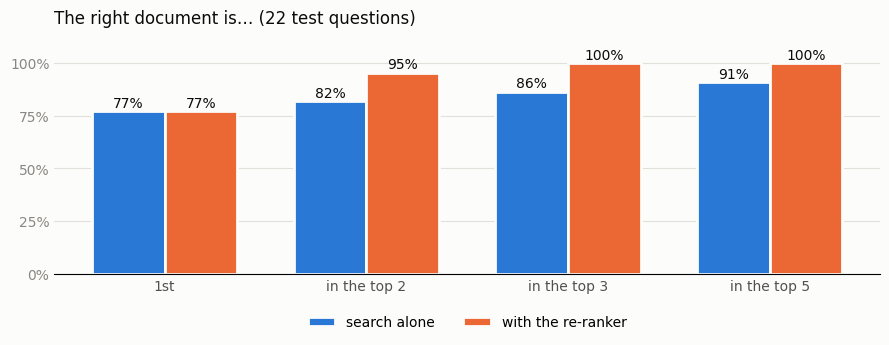

In [18]:
# @title How often search finds the right document { display-mode: "form" }
import matplotlib.pyplot as plt

search_cases = [case for case in load_eval_set(EVAL_30_PATH) if case.get("expected_sources")]
CUTOFFS = (1, 2, 3, 5)


def found_rates(search):
    """For each cut-off: the share of questions whose right document is within that many results."""
    found = {cutoff: 0 for cutoff in CUTOFFS}
    for case in search_cases:
        documents = [chunk.doc_id for chunk in search(case["question"], k=max(CUTOFFS))]
        for cutoff in CUTOFFS:
            found[cutoff] += any(doc in documents[:cutoff] for doc in case["expected_sources"])
    return [found[cutoff] / len(search_cases) for cutoff in CUTOFFS]


rates = {"search alone": found_rates(retriever.hybrid_search), "with the re-ranker": found_rates(reranked_search)}

display(HTML(reranker_label()))
figure, ax = plt.subplots(figsize=(9, 3.6), facecolor="#fcfcfb")
for number, (name, values) in enumerate(rates.items()):
    positions = [index + (number - 0.5) * 0.36 for index in range(len(CUTOFFS))]
    ax.bar(positions, values, width=0.36, color=[BLUE, ORANGE][number], label=name, edgecolor="#fcfcfb", linewidth=2)
    for position, value in zip(positions, values):
        ax.text(position, value + 0.02, f"{value:.0%}", ha="center", color=INK, fontsize=10)
ax.set_xticks(range(len(CUTOFFS)), ["1st", "in the top 2", "in the top 3", "in the top 5"], color=SOFT_INK)
ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"], color=GREY)
ax.set_title(f"The right document is… ({len(search_cases)} test questions)", loc="left", color=INK)
ax.set_facecolor("#fcfcfb")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
figure.tight_layout()
plt.show()

Now the 15 test questions, both ways, with the model answering.

pipeline,category,needs human,sources,seconds per question,tokens per question,cost per question
hybrid,87%,100%,93%,2.52,2346,$0.00634
hybrid + re-ranker,87%,100%,100%,9.4,2370,$0.00628


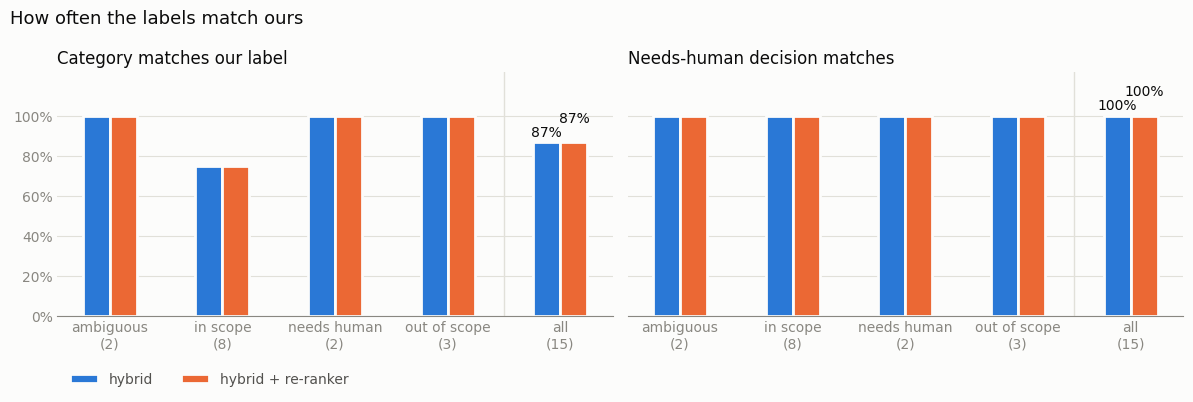

In [19]:
# @title Run the 15 test questions both ways { display-mode: "form" }
cases = load_eval_set()


def evaluate(label, search):
    results = score(run_eval(lambda question: answer_cited(question, search=search), cases))
    costs = [result.get("cost") for result in results]
    return results, {
        "pipeline": label,
        "category": f"{sum(r['category_ok'] for r in results) / len(results):.0%}",
        "needs human": f"{sum(r['needs_human_ok'] for r in results) / len(results):.0%}",
        "sources": f"{sum(bool(r['sources_ok']) for r in results) / len(results):.0%}",
        "seconds per question": round(sum(r["seconds"] for r in results) / len(results), 2),
        "tokens per question": round(sum(r.get("tokens", 0) for r in results) / len(results)),
        "cost per question": format_cost(None if None in costs else sum(costs) / len(costs)),
    }


display(HTML(reranker_label()))
hybrid_results, hybrid_row = evaluate("hybrid", retriever.hybrid_search)
reranked_results, reranked_row = evaluate("hybrid + re-ranker", reranked_search)
show_table([hybrid_row, reranked_row], "Search alone vs. with the re-ranker")
plot_pass_rates(
    {"hybrid": hybrid_results, "hybrid + re-ranker": reranked_results},
    "How often the labels match ours",
)

pipeline,category,needs human,sources,seconds per question,tokens per question,cost per question
hybrid,87%,100%,93%,2.52,2346,$0.00634
hybrid + re-ranker,87%,100%,100%,9.4,2370,$0.00628
hybrid + model re-ranker,93%,100%,100%,5.23,2309,$0.00594


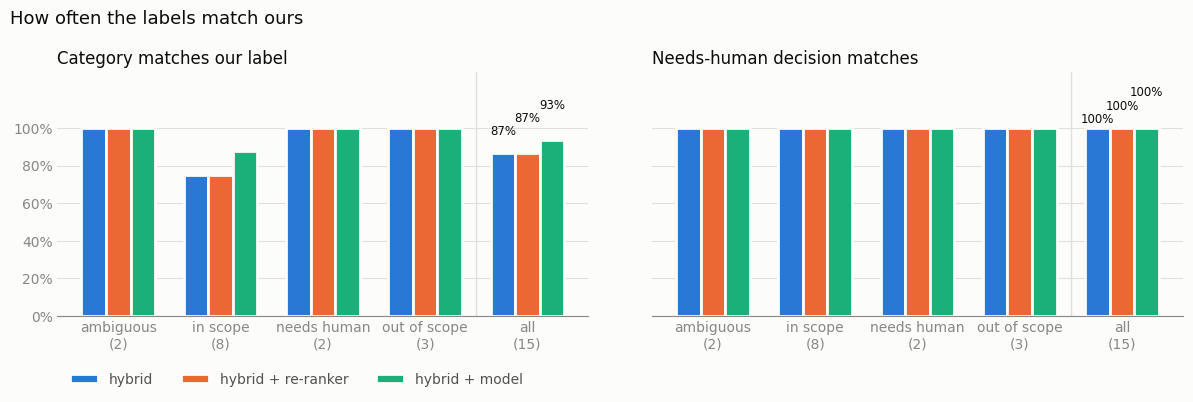

In [21]:
# @title The model as the re-ranker { display-mode: "form" }
RUN_MODEL_RERANKER = True  # @param {type:"boolean"}


def model_reranked_search(question, k=5, audiences=EVERYONE, pool=20):
    candidates = retriever.hybrid_search(question, k=pool, audiences=audiences)
    listing = "\n".join(f"[{i}] {chunk.text[:400]}" for i, chunk in enumerate(candidates))
    reply = chat(
        f"Question: {question}\n\nPassages:\n{listing}\n\n"
        f'Return only JSON: {{"best": [the numbers of the {k} most useful passages, best first]}}',
        max_tokens=4000,
    )
    return [candidates[i] for i in parse_json(reply.text)["best"][:k]]


if RUN_MODEL_RERANKER:
    model_results, model_row = evaluate("hybrid + model re-ranker", model_reranked_search)
    show_table([hybrid_row, reranked_row, model_row], "Three pipelines")
    plot_pass_rates(
        {"hybrid": hybrid_results, "hybrid + re-ranker": reranked_results, "hybrid + model": model_results},
        "How often the labels match ours",
    )
else:
    display(HTML(f'<div style="color:{SOFT_INK}">Switched off. Tick the box and run this step to compare.</div>'))